In [1]:
!pip install --quiet numpy pandas matplotlib scikit-learn imbalanced-learn joblib seaborn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, accuracy_score
from imblearn.over_sampling import SMOTE
import joblib

# plotting defaults
%matplotlib inline
plt.rcParams['figure.figsize'] = (8,4)
sns.set(style='whitegrid')

In [3]:
# Edit this if your file is somewhere else
DATA_PATH = "exoTrain.csv"

# Load without header (many Kaggle variants have no header)
df = pd.read_csv(DATA_PATH, header=None)
print("Dataframe shape:", df.shape)
print("First 3 rows (labels + start of flux):")
display(df.head(3))

C:\Users\Shreyansh\AppData\Local\Temp\ipykernel_8956\1468356594.py:5: DtypeWarning: Columns (0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,195,196,197,198,199,200,201,202,203,204,205,206,207,208,209,210,211,212,213,214,215,216,217,218,219,220,221,222,223,224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,250,251,252,253,2

Dataframe shape: (5088, 3198)
First 3 rows (labels + start of flux):


,0,1,2,3,4,5,6,7,8,9,...,3188,3189,3190,3191,3192,3193,3194,3195,3196,3197
0,LABEL,FLUX.1,FLUX.2,FLUX.3,FLUX.4,FLUX.5,FLUX.6,FLUX.7,FLUX.8,FLUX.9,...,FLUX.3188,FLUX.3189,FLUX.3190,FLUX.3191,FLUX.3192,FLUX.3193,FLUX.3194,FLUX.3195,FLUX.3196,FLUX.3197
1,2,93.85,83.81,20.1,-26.98,-39.56,-124.71,-135.18,-96.27,-79.89,...,-78.07,-102.15,-102.15,25.13,48.57,92.54,39.32,61.42,5.08,-39.54
2,2,-38.88,-33.83,-58.54,-40.09,-79.31,-72.81,-86.55,-85.33,-83.97,...,-3.28,-32.21,-32.21,-24.89,-4.86,0.76,-11.7,6.46,16,19.93


In [6]:
import numpy as np
import pandas as pd

# assume df already loaded (pd.read_csv(...))
raw = df.iloc[:, 0].astype(str).str.strip()            # read first column as text
# If the first cell looks like a header name, re-read file with header=0
if raw.iloc[0].lower().isalpha() or 'label' in raw.iloc[0].lower():
    df = pd.read_csv("exoTrain.csv", header=0, dtype=object)
    raw = df.iloc[:, 0].astype(str).str.strip()

# Try numeric conversion (handles '1','2','2.0')
nums = pd.to_numeric(raw, errors='coerce')
# If numeric conversion failed for some, try simple digit-extraction
if nums.isna().any():
    extracted = raw.str.extract(r'(-?\d+\.?\d*)', expand=False)
    nums[nums.isna()] = pd.to_numeric(extracted[nums.isna()], errors='coerce')

# Final fallback mappings for common words
text = raw.str.lower()
nums[text.isin(['exo','exoplanet','planet','positive','yes','p'])] = 2
nums[text.isin(['non-exo','nonexo','negative','no','n'])] = 1

# Drop rows we still can't parse (rare)
mask = ~nums.isna()
if mask.sum() != len(nums):
    print(f"Dropping {len(nums)-mask.sum()} rows with unreadable labels.")
    df = df.loc[mask].reset_index(drop=True)
    nums = nums[mask].reset_index(drop=True)

labels = nums.astype(int)
# Convert common 1/2 encoding to 0/1 where 1 = exoplanet
if set(labels.unique()) == {1,2}:
    y = (labels == 2).astype(int).values
elif set(labels.unique()) == {0,1}:
    y = labels.values
else:
    # fallback: treat max numeric value as positive
    y = (labels == labels.max()).astype(int).values

X = df.iloc[:, 1:].apply(pd.to_numeric, errors='coerce').values
# fill any NaNs in X with column means
if np.isnan(X).any():
    col_mean = np.nanmean(X, axis=0)
    inds = np.where(np.isnan(X))
    X[inds] = np.take(col_mean, inds[1])

print("Done: X shape:", X.shape, " y counts:", np.bincount(y))
#Data PreProcessing - Converting Labels as 1 -> Exoplanet and 0 -> Non-Exoplanet
#Getting the Shape of data
#X -> Number of Stars and It's Flux (Brightness) Values
#y -> Number Of Stars and It's Exoplanet OR Not

Done: X shape: (5087, 3197)  y counts: [5050   37]


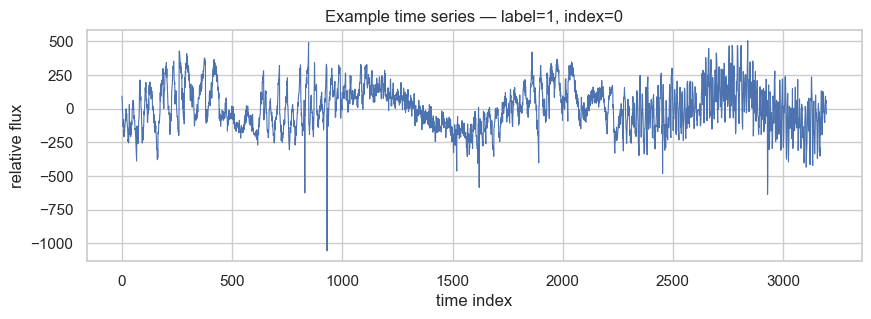

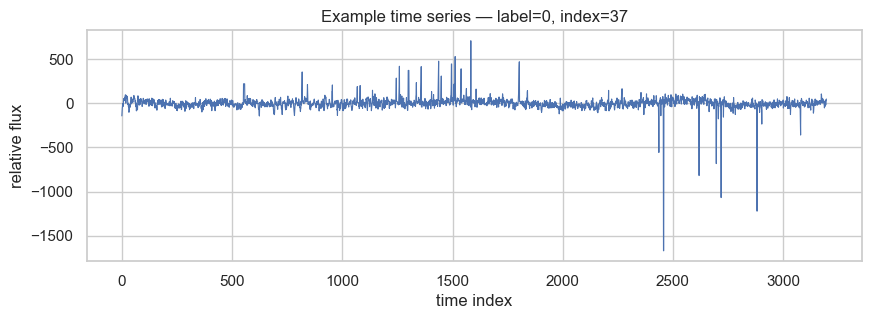

In [7]:
def plot_example(X, y, label=1, idx=None):
    ids = np.where(y == label)[0]
    if len(ids) == 0:
        print("No examples of label", label)
        return
    i = ids[0] if idx is None else ids[idx]
    plt.figure(figsize=(10,3))
    plt.plot(X[i], linewidth=0.8)
    plt.title(f"Example time series — label={label}, index={i}")
    plt.xlabel("time index")
    plt.ylabel("relative flux")
    plt.show()

# show a positive (exoplanet) example if available, then a negative
plot_example(X, y, label=1)
plot_example(X, y, label=0)
#PLots of Exoplanet and Non-Exoplanet 
#Dips and Valley -> Something came in front of that star 
#No dips and Valley -> Nothing came means no planet revovling around it.

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaling done.")
print("Mean of X_scaled:", X_scaled.mean())
print("Std of X_scaled:", X_scaled.std())


Scaling done.
Mean of X_scaled: -5.723439883565721e-20
Std of X_scaled: 1.0


In [11]:
#Splitting into Train and Test
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)
print("Train class counts:", np.bincount(y_train))
print("Test class counts:", np.bincount(y_test))

Train size: (4069, 3197)
Test size: (1018, 3197)
Train class counts: [4039   30]
Test class counts: [1011    7]


In [10]:
#Balancing Data using SMOTE (Synthetic Minority Oversampling Technique) 
#Too many nonplanets so model would think everything is nonplanet, to balance this we use SMOTE
#To make Learning Fair
from imblearn.over_sampling import SMOTE

sm = SMOTE(random_state=42)
X_train_bal, y_train_bal = sm.fit_resample(X_train, y_train)

print("Before SMOTE:", np.bincount(y_train))
print("After SMOTE:", np.bincount(y_train_bal))

Before SMOTE: [4039   30]
After SMOTE: [4039 4039]


In [12]:
#Training Logistic Regression
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=2000)
log_reg.fit(X_train_bal, y_train_bal)
print("Logistic Regression trained.")

Logistic Regression trained.


In [13]:
#Training KNN
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_bal, y_train_bal)
print("KNN trained.")

KNN trained.


In [15]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

def evaluate_model(model, X_test, y_test, model_name="Model"):
    """
    Prints accuracy, classification report, and plots confusion matrix.
    """
    print("="*50)
    print(f"Evaluation for: {model_name}")
    print("="*50)

    # predictions
    y_pred = model.predict(X_test)

    # --- Accuracy ---
    acc = accuracy_score(y_test, y_pred)
    print(f"Accuracy: {acc:.4f}\n")

    # --- Detailed report ---
    print("Classification Report:")
    print(classification_report(y_test, y_pred, digits=4))

    # --- Confusion matrix ---
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix:\n", cm)

    # --- Pretty Confusion Matrix Plot ---
    plt.figure(figsize=(4,3))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["No Planet (0)", "Planet (1)"],
        yticklabels=["No Planet (0)", "Planet (1)"]
    )
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"Confusion Matrix: {model_name}")
    plt.show()

    return y_pred


Evaluation for: Logistic Regression
Accuracy: 0.9479

Classification Report:
              precision    recall  f1-score   support

           0     0.9938    0.9535    0.9732      1011
           1     0.0208    0.1429    0.0364         7

    accuracy                         0.9479      1018
   macro avg     0.5073    0.5482    0.5048      1018
weighted avg     0.9871    0.9479    0.9668      1018

Confusion Matrix:
 [[964  47]
 [  6   1]]


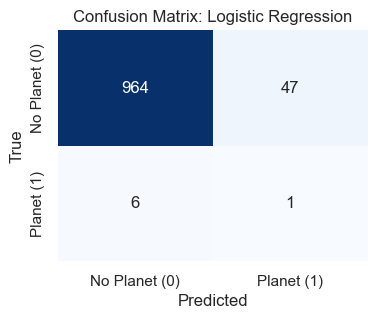

Evaluation for: KNN
Accuracy: 0.9558

Classification Report:
              precision    recall  f1-score   support

           0     0.9949    0.9604    0.9774      1011
           1     0.0476    0.2857    0.0816         7

    accuracy                         0.9558      1018
   macro avg     0.5212    0.6231    0.5295      1018
weighted avg     0.9884    0.9558    0.9712      1018

Confusion Matrix:
 [[971  40]
 [  5   2]]


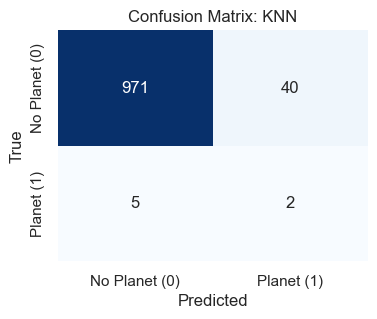

array([0, 0, 0, ..., 0, 0, 0])

In [16]:
evaluate_model(log_reg, X_test, y_test, "Logistic Regression")
evaluate_model(knn, X_test, y_test, "KNN")